# Episode 002 · Coordinate frames

**Question:** how can the same point have different coordinates in the world,
robot, and sensor frames?

Work through five experiments in order. Before moving a slider, make a
prediction. After releasing it, compare the picture and the numbers.

1. Move an origin.
2. Rotate the axes.
3. Combine translation and rotation.
4. Reverse the transformation.
5. Mount a sensor and compose two transformations.

The world and robot move on a plane. Lengths use **meters**. The robot's +x axis
points forward and +y points left. Positive angles turn counterclockwise.
Slider angles use degrees for readability; the calculations convert them to radians.

Use **Restart Kernel and Run All Cells** in JupyterLab. The saved reference
figures are visible without a live kernel; live sliders require executing the
notebook. Setup and verification commands are in [the episode guide](README.md).
Drawing support is in `plotting.py`; the mathematics under study is in these cells.

In [1]:
# Voiceover: We compare one fixed landmark in different coordinate frames.
# Positions use meters, and the calculations use radians for angles.
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from plotting import show_experiment, WORLD_COLOR, ROBOT_COLOR, SENSOR_COLOR

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 100})
world_from_world = np.eye(3)
landmark_world = np.array([2.0, 1.0])

def slider(label, minimum, maximum, value, step=0.25):
    return widgets.FloatSlider(description=label, min=minimum, max=maximum,
                               value=value, step=step, continuous_update=False,
                               style={"description_width": "110px"},
                               layout=widgets.Layout(width="360px"))

## 1. Move the origin

Keep the landmark at world coordinates $(2,1)$. The robot's axes initially
point in the same directions as the world's axes.

Moving the robot's origin to $t=(t_x,t_y)$ gives
$p_{robot}=p_{world}-t$. The physical landmark stays where it was.

**Predict:** if the robot origin moves one meter right, does the landmark's
local x coordinate increase or decrease? Look at both panels after moving the slider.

### The world_from_robot matrix

Let $(x_r,y_r)$ be the coordinates of a point in the robot frame, and
$(x_w,y_w)$ the coordinates of the same point in the world frame.

`world_from_robot` describes the robot frame's position and orientation
relative to the world. It converts robot coordinates into world coordinates.

When both origins coincide and their axes point in the same directions,
this transformation is the identity matrix, created by `np.eye(3)`:

$$
\begin{bmatrix}
x_w \\ y_w \\ 1
\end{bmatrix}
=
\begin{bmatrix}
1 & 0 & 0 \\
0 & 1 & 0 \\
0 & 0 & 1
\end{bmatrix}
\begin{bmatrix}
x_r \\ y_r \\ 1
\end{bmatrix}
=
\begin{bmatrix}
x_r \\ y_r \\ 1
\end{bmatrix}.
$$

In the code below, `world_from_robot[:2, 2] = translation` places
$(t_x,t_y)$ in the first two entries of the last column.
These are the coordinates of the **robot's origin in the world frame**.

Now the robot has moved, so the origin of the robot and the origin of the world do not align.
What we do here is measure distances (coordinates) from the robot's origin and then want to translate them to the world coordinate systeam.

So if the robot is 2 meters away from the world origin and it measures a point 1 meter away from it in the x-axis, then it's obvious that the origin is 2+1 meters away from that point

The axes remain aligned, but the origins are now separated:

$$
\begin{bmatrix}
x_w \\ y_w \\ 1
\end{bmatrix}
=
\begin{bmatrix}
1 & 0 & t_x \\
0 & 1 & t_y \\
0 & 0 & 1
\end{bmatrix}
\begin{bmatrix}
x_r \\ y_r \\ 1
\end{bmatrix}
=
\begin{bmatrix}
x_r+t_x \\ y_r+t_y \\ 1
\end{bmatrix}.
$$

The extra coordinate $1$ makes the translation possible through matrix
multiplication. The point still has two physical coordinates, $x$ and $y$.

This matrix maps **robot → world**. To express our fixed world landmark
in robot coordinates, we reverse that translation:

$$
p_{\text{robot}} = p_{\text{world}} - t.
$$

What does that mean? If we know the measurement from the origin and its 3 meters away in the x-axis, and the robot is 1 meter away in the x-axis in the same direction
then the robot is closer to the point by 1 meter. This is why we subtract.

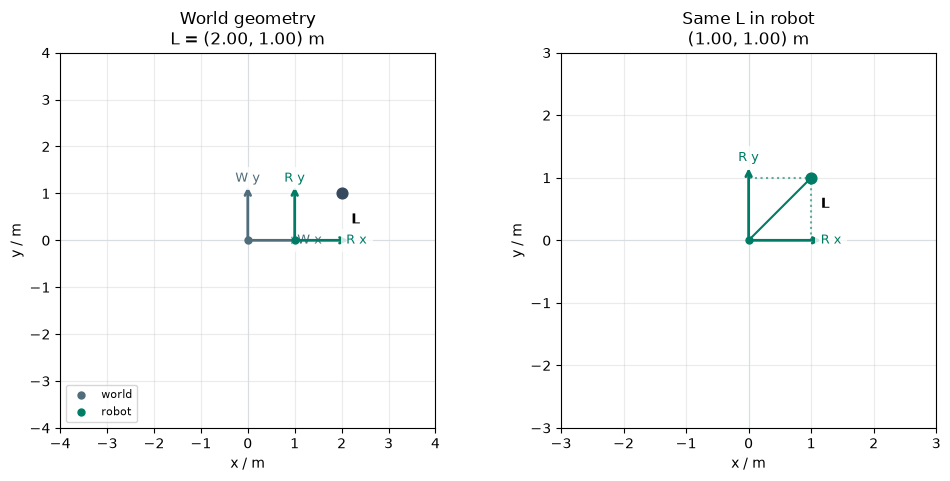

World L: [2. 1.] m   Robot L: [1. 1.] m


In [2]:
# Voiceover: Keep the world landmark fixed and move the robot origin.
# Subtract that origin because we want the landmark's robot coordinates.
def translation_experiment(origin_x=1.0, origin_y=0.0):
    translation = np.array([origin_x, origin_y])  # array([1., 0.])
    landmark_robot = landmark_world - translation # [2, 1] - [1, 0] = [1, 1]
    world_from_robot = np.eye(3) # Identity 3x3 matrix
    world_from_robot[:2, 2] = translation # look above for an explanation
    show_experiment([
        ("world", world_from_world, WORLD_COLOR),
        ("robot", world_from_robot, ROBOT_COLOR),
    ], landmark_world, [("robot", landmark_robot, ROBOT_COLOR)]) # this just shows the original coordinate system, the new world system and how that changes measuring.
    print(f"World L: {landmark_world} m   Robot L: {landmark_robot} m")
    return landmark_robot

np.testing.assert_allclose(translation_experiment(1, 0), [1, 1])  # this runs the function and checks the answer is correct.

In [3]:
# Voiceover: Just play with the sliders to get a feeling how changing the origin affects coordinates
translation_lab = widgets.interactive(
    translation_experiment,
    origin_x=slider("Origin x / m", -3, 3, 1),
    origin_y=slider("Origin y / m", -3, 3, 0),
)
display(translation_lab)

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Origin x / m', layout=Layou…

## 2. Rotate the axes

Now keep both origins at zero and rotate the robot axes. A positive angle
turns robot +x toward world +y.

$$R(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta\\
\sin\theta&\cos\theta\end{bmatrix}$$

$R$ maps robot coordinates to world coordinates. To express our fixed world
point in the robot frame, use $R^T$. A rotation preserves distances and right angles.

**Predict:** at $90^\circ$, world $(2,1)$ has robot coordinates $(1,-2)$.
Which drawn axis explains the negative coordinate?

### The world_from_robot matrix

Now both origins remain at zero, and the robot's axes rotate by an angle
$\theta$. A positive angle turns robot $+x$ toward world $+y$.

The columns of the rotation matrix describe the robot's unit axes
expressed in world coordinates:

$$
R(\theta)=
\begin{bmatrix}
\cos\theta & -\sin\theta \\
\sin\theta & \cos\theta
\end{bmatrix}.
$$

The code `world_from_robot[:2, :2] = rotation` replaces the upper-left
identity block with this rotation. The translation column stays zero:

$$
\begin{bmatrix}
x_w \\ y_w \\ 1
\end{bmatrix}
=
\begin{bmatrix}
\cos\theta & -\sin\theta & 0 \\
\sin\theta & \cos\theta & 0 \\
0 & 0 & 1
\end{bmatrix}
\begin{bmatrix}
x_r \\ y_r \\ 1
\end{bmatrix}
=
\begin{bmatrix}
x_r\cos\theta-y_r\sin\theta \\
x_r\sin\theta+y_r\cos\theta \\
1
\end{bmatrix}.
$$

Again, this maps **robot → world** (we know the robot coordinates, and we want to find the world coordinates). Our experiment starts with a fixed
world landmark and asks for its robot coordinates, so we use the inverse
rotation. For a rotation matrix, the inverse equals the transpose:

$$
R(\theta)^{-1}=R(\theta)^T=R(-\theta).
$$

Therefore, `rotation.T @ landmark_world` calculates (we know the world coordinates and want to find the robot coordinates):

$$
\begin{bmatrix}
x_r \\ y_r
\end{bmatrix}
=
\begin{bmatrix}
\cos\theta & \sin\theta \\
-\sin\theta & \cos\theta
\end{bmatrix}
\begin{bmatrix}
x_w \\ y_w
\end{bmatrix}.
$$

For example, at $\theta=90^\circ$, our world landmark $(2,1)$ becomes:

$$
\begin{bmatrix}
x_r \\ y_r
\end{bmatrix}
=
\begin{bmatrix}
0 & 1 \\
-1 & 0
\end{bmatrix}
\begin{bmatrix}
2 \\ 1
\end{bmatrix}
=
\begin{bmatrix}
1 \\ -2
\end{bmatrix}.
$$

The landmark stays in the same physical location. We measure it using
axes that point in different directions.

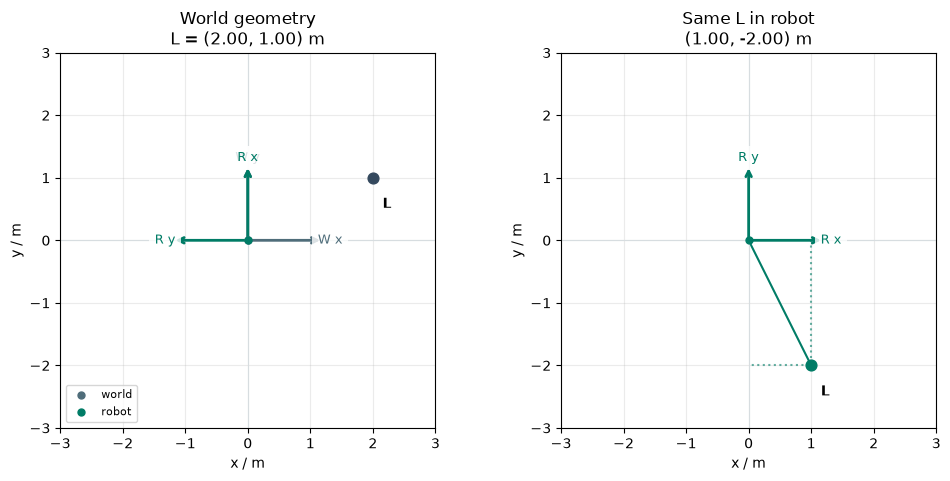

Robot-to-world rotation:
 [[ 0. -1.]
 [ 1.  0.]]
World L: [2. 1.] m   Robot L: [ 1. -2.] m


In [4]:
# Voiceover: The columns of the rotation matrix are the robot's unit axes
# expressed in the world. Its transpose reads a world point in those axes.
def rotation_matrix(heading_degrees):
    theta = np.deg2rad(heading_degrees)
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])

def rotation_experiment(heading=90.0):
    rotation = rotation_matrix(heading)
    landmark_robot = rotation.T @ landmark_world
    world_from_robot = np.eye(3)
    world_from_robot[:2, :2] = rotation
    show_experiment([
        ("world", world_from_world, WORLD_COLOR),
        ("robot", world_from_robot, ROBOT_COLOR),
    ], landmark_world, [("robot", landmark_robot, ROBOT_COLOR)])
    print("Robot-to-world rotation:\n", rotation)
    print(f"World L: {landmark_world} m   Robot L: {landmark_robot} m")
    np.testing.assert_allclose(np.linalg.norm(landmark_robot), np.linalg.norm(landmark_world))
    return landmark_robot

np.testing.assert_allclose(rotation_experiment(90), [1, -2], atol=1e-12)

In [5]:
# Voiceover: Turn the axes through positive and negative quarter turns.
# Follow the axis arrows first, then use their directions to explain the numbers.
rotation_lab = widgets.interactive(
    rotation_experiment,
    heading=slider("Heading / deg", -180, 180, 90, step=15),
)
display(rotation_lab)

interactive(children=(FloatSlider(value=90.0, continuous_update=False, description='Heading / deg', layout=Lay…

## 3. Combine rotation and translation

Name the direction explicitly: `world_from_robot` takes robot coordinates
and returns world coordinates. Rotate the local point, then add the robot origin.

$$p_{world}=R\,p_{robot}+t,\qquad
\begin{bmatrix}p_{world}\\1\end{bmatrix}
=\underbrace{\begin{bmatrix}R&t\\0\;0&1\end{bmatrix}}_{T_{world\leftarrow robot}}
\begin{bmatrix}p_{robot}\\1\end{bmatrix}.$$

The third coordinate is one for a point, so the matrix can include translation.
The helper below reads it back as an ordinary two-dimensional point.

**Predict:** with robot pose $(2,1,90^\circ)$, local point $(1,0)$ becomes
world point $(2,2)$. Rotating after translating would give a different result.

### The world_from_robot matrix

The robot frame now has both an orientation $\theta$ and an origin
$t=(t_x,t_y)$ expressed in world coordinates.

To locate a robot-frame point in the world, we:

1. Rotate its local displacement into the directions of the world axes.
2. Add the position of the robot's origin.

Therefore:

$$
p_{\text{world}} = R(\theta)\,p_{\text{robot}} + t.
$$

In the code, we fill two parts of the same matrix:

- `world_from_robot[:2, :2] = rotation` sets the orientation.
- `world_from_robot[:2, 2] = translation` sets the origin.

Together, they give:

$$
\begin{bmatrix}
x_w \\ y_w \\ 1
\end{bmatrix}
=
\underbrace{
\begin{bmatrix}
\cos\theta & -\sin\theta & t_x \\
\sin\theta & \cos\theta & t_y \\
0 & 0 & 1
\end{bmatrix}
}_{T_{\text{world}\leftarrow\text{robot}}}
\begin{bmatrix}
x_r \\ y_r \\ 1
\end{bmatrix}
=
\begin{bmatrix}
x_r\cos\theta-y_r\sin\theta+t_x \\
x_r\sin\theta+y_r\cos\theta+t_y \\
1
\end{bmatrix}.
$$

The upper-left block describes the directions of the robot's axes.
The last column describes where those axes begin.

**Example:** place the robot at world position $(2,1)$ with a heading
of $90^\circ$. A point one meter forward in the robot frame has local
coordinates $(1,0)$:

$$
\begin{bmatrix}
x_w \\ y_w \\ 1
\end{bmatrix}
=
\begin{bmatrix}
0 & -1 & 2 \\
1 & 0 & 1 \\
0 & 0 & 1
\end{bmatrix}
\begin{bmatrix}
1 \\ 0 \\ 1
\end{bmatrix}
=
\begin{bmatrix}
2 \\ 2 \\ 1
\end{bmatrix}.
$$

The robot's forward direction now points along world $+y$,

Known example: robot (1, 0) -> world [2. 2.]


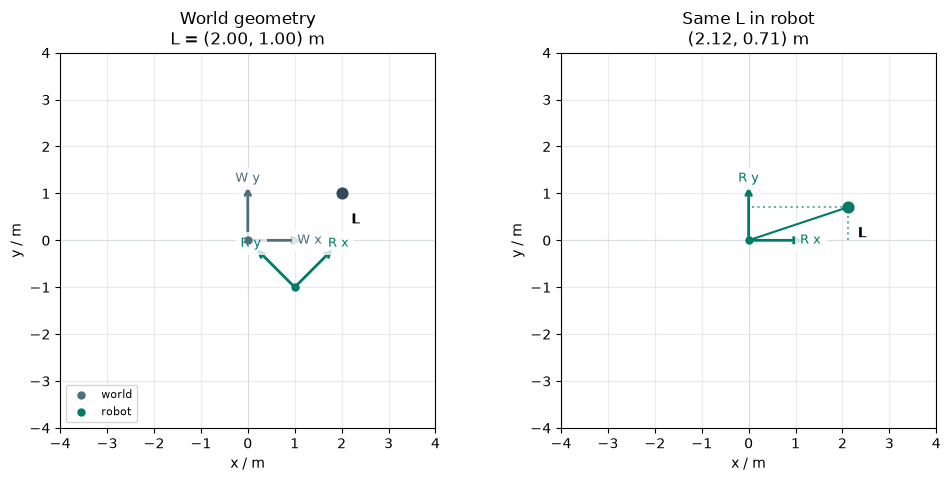

world_from_robot:
 [[ 0.707 -0.707  1.   ]
 [ 0.707  0.707 -1.   ]
 [ 0.     0.     1.   ]]
Robot L: [2.121 0.707] m


array([2.121, 0.707])

In [6]:
# Voiceover: We combine the ideas we already saw in a three-by-three matrix.
# The last column is the robot origin, expressed in world meters.
def rigid_transform(x, y, heading_degrees): # this matrix transforms measurements from the (x,y,headging) coordinate system to the world coordinate system
    matrix = np.eye(3)
    matrix[:2, :2] = rotation_matrix(heading_degrees)
    matrix[:2, 2] = [x, y]
    return matrix

def transform_point(transformation_matrix, point_in_source):
    homogeneous_point = np.append(np.asarray(point_in_source, dtype=float), 1.0) # append the 1.0 as a z coordinate
    return (transformation_matrix @ homogeneous_point)[:2] # calculates A*V.T and keeps the first two coordinates

quarter_turn = rigid_transform(2, 1, 90)
np.testing.assert_allclose(transform_point(quarter_turn, [1, 0]), [2, 2], atol=1e-12)
print("Known example: robot (1, 0) -> world", transform_point(quarter_turn, [1, 0]))

def rigid_experiment(robot_x=1.0, robot_y=-1.0, heading=45.0):
    world_from_robot = rigid_transform(robot_x, robot_y, heading) # world_from_robot * robot_coordinates = world_coordinates
    # Solve T p_robot = p_world. The next experiment derives T's explicit inverse.
    landmark_robot = np.linalg.solve(world_from_robot, np.append(landmark_world, 1))[:2] # this solves robot_coorindates = inverse(world_from_robot) * world_coordinate
    show_experiment([
        ("world", world_from_world, WORLD_COLOR),
        ("robot", world_from_robot, ROBOT_COLOR),
    ], landmark_world, [("robot", landmark_robot, ROBOT_COLOR)])
    print("world_from_robot:\n", world_from_robot)
    print(f"Robot L: {landmark_robot} m")
    return landmark_robot

rigid_experiment()

In [7]:
# Voiceover: Change position and heading together. The robot axes move and
# turn, while the world landmark stays fixed. Every number describes that picture.
rigid_lab = widgets.interactive(
    rigid_experiment,
    robot_x=slider("Robot x / m", -3, 3, 1),
    robot_y=slider("Robot y / m", -3, 3, -1),
    heading=slider("Heading / deg", -180, 180, 45, step=15),
)
display(rigid_lab)

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Robot x / m', layout=Layout…

## 4. Reverse the transformation

Let's reverse the problem.
We know the landmark's **world coordinates**, the robot's world position
$t$, and its orientation $R$. We want the landmark's **robot coordinates**:
how far forward and to the left is it relative to the robot?

The forward transformation takes robot coordinates and produces world
coordinates. Our known point is already in the world frame, so we need
the reverse direction.

First subtract the robot's origin, then undo its rotation:

$$
p_{\text{robot}} = R^T\left(p_{\text{world}}-t\right).
$$

The landmark stays in place; we describe its position using the robot's axes.
Start with:

$$
p_{\text{robot}}=R^T p_{\text{world}}+(-R^Tt).
$$

For clarity, name the entries:

$$
R^T=\begin{bmatrix}a&b\\c&d\end{bmatrix},
\qquad
-R^Tt=\begin{bmatrix}u\\v\end{bmatrix}.
$$

Our equation now says:

$$
\begin{bmatrix}x_r\\y_r\end{bmatrix}
=
\begin{bmatrix}a&b\\c&d\end{bmatrix}
\begin{bmatrix}x_w\\y_w\end{bmatrix}
+
\begin{bmatrix}u\\v\end{bmatrix}
=
\begin{bmatrix}
a x_w+b y_w+u\\
c x_w+d y_w+v
\end{bmatrix}.
$$

We can produce those same results with **one matrix multiplication**, using the extra coordinate \(1\):

$$
\begin{bmatrix}x_r\\y_r\\1\end{bmatrix}
=
\begin{bmatrix}
a&b&u\\
c&d&v\\
0&0&1
\end{bmatrix}
\begin{bmatrix}x_w\\y_w\\1\end{bmatrix}.
$$

The first row produces $(a x_w+b y_w+u\cdot1)$. The second produces $(c x_w+d y_w+v\cdot1)$. The last row preserves the extra $(1)$.

Now recognize the blocks: the upper-left block is $(R^T)$, and the last column’s upper two entries are $(-R^Tt)$. Therefore:

$$
\boxed{
T^{-1}=
\begin{bmatrix}
R^T&-R^Tt\\
0\;\;0&1
\end{bmatrix}
}
$$

This matrix is $(T^{-1})$ because it converts world coordinates back into robot coordinates, undoing the original transformation.

The green ring marks the point recovered after world → robot → world.
It should overlap the original landmark. The residual reports numerical rounding error.

**Predict:** the inverse of pose $(2,1,90^\circ)$ has translation $(-1,2)$.
Try it below and explain why it is different from $(-2,-1)$.

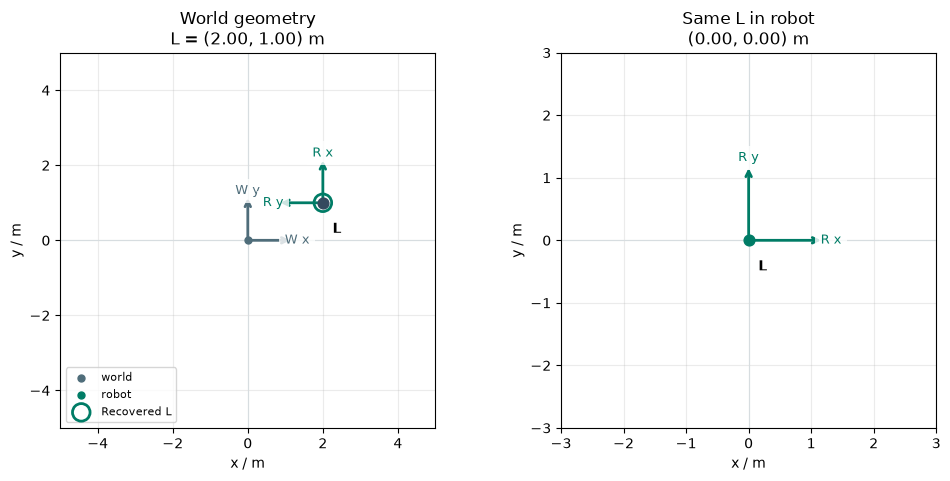

robot_from_world:
 [[ 0.  1. -1.]
 [-1.  0.  2.]
 [ 0.  0.  1.]]
Round-trip error: 0.00e+00 m


np.float64(0.0)

In [8]:
# Voiceover: Reversing a transform undoes both operations in reverse order.
# We check it by returning the landmark to its original world coordinates.
def inverse_transform(target_from_source):
    rotation = target_from_source[:2, :2]
    translation = target_from_source[:2, 2]
    inverse = np.eye(3)
    inverse[:2, :2] = rotation.T
    inverse[:2, 2] = -rotation.T @ translation
    return inverse

np.testing.assert_allclose(inverse_transform(quarter_turn)[:2, 2], [-1, 2], atol=1e-12)

def inverse_experiment(robot_x=2.0, robot_y=1.0, heading=90.0):
    world_from_robot = rigid_transform(robot_x, robot_y, heading) # the TRANSFORMATION MATRIX for ROBOT-> WORLD transformation
    robot_from_world = inverse_transform(world_from_robot) # the TRANSFORMATION MATRIX for ROBOT <- WORLD transformation
    landmark_robot = transform_point(robot_from_world, landmark_world) # robot_from_world x landmark_world -> Landmark in robot coordinates
    recovered = transform_point(world_from_robot, landmark_robot) # and back using world_from_robot x landmark_robot
    show_experiment([
        ("world", world_from_world, WORLD_COLOR),
        ("robot", world_from_robot, ROBOT_COLOR),
    ], landmark_world, [("robot", landmark_robot, ROBOT_COLOR)], recovered=recovered)
    print("robot_from_world:\n", robot_from_world)
    residual = np.linalg.norm(recovered - landmark_world)
    print(f"Round-trip error: {residual:.2e} m")
    np.testing.assert_allclose(recovered, landmark_world, atol=1e-12)
    return residual

inverse_experiment()

In [9]:
# Voiceover: Try translated and rotated poses, including negative angles.
# The recovered-point ring keeps showing whether the two directions agree.
inverse_lab = widgets.interactive(
    inverse_experiment,
    robot_x=slider("Robot x / m", -3, 3, 2),
    robot_y=slider("Robot y / m", -3, 3, 1),
    heading=slider("Heading / deg", -180, 180, 90, step=15),
)
display(inverse_lab)

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='Robot x / m', layout=Layout…

## 5. Find a landmark's coordinates relative to a mounted sensor

A sensor has its own origin and axes. For example, a sensor mounted near
the front of a robot measures positions relative to that mounting location
and the direction it faces.

### 1. State what we know and what we want

We know:

- The landmark's world position: L3 is at $(5,2)$.
- The robot's world pose: position $(2,1)$ and heading $90^\circ$.
- The sensor's mounting relative to the robot: $0.25$ meters forward,
  $0.10$ meters left, and turned $30^\circ$ relative to the robot's axes.

We want to find the landmark's **sensor coordinates**: where is L3 relative
to the sensor's origin and axes?

The robot and sensor frames would coincide if all three mounting values
were zero. Our default values give them different origins and orientations.

### 2. Build the robot-to-world transformation

We know the robot's position and heading in the world, so we build:

`world_from_robot = rigid_transform(robot_x, robot_y, heading)`

This matrix converts a point from robot coordinates into world coordinates.

### 3. Build the sensor-to-robot transformation

We know the sensor's position and heading relative to the robot, so we build:

`robot_from_sensor = rigid_transform(mount_x, mount_y, mount_heading)`

This matrix converts a point from sensor coordinates into robot coordinates.

For example, the sensor's own origin has sensor coordinates $(0,0)$.
Applying `robot_from_sensor` places that origin at robot coordinates
$(0.25,0.10)$.

### 4. Join those two transformations

To convert a sensor-coordinate point into world coordinates, we can
take two steps:

**sensor → robot → world**

$$
p_{\text{robot}}
=
T_{\text{robot}\leftarrow\text{sensor}}\,p_{\text{sensor}},
$$

then:

$$
p_{\text{world}}
=
T_{\text{world}\leftarrow\text{robot}}\,p_{\text{robot}}.
$$

Substituting the first equation into the second gives:

$$
p_{\text{world}}
=
\left(
T_{\text{world}\leftarrow\text{robot}}
T_{\text{robot}\leftarrow\text{sensor}}
\right)
p_{\text{sensor}}.
$$

Therefore, one matrix can represent both steps:

`world_from_sensor = world_from_robot @ robot_from_sensor`

The right-hand matrix acts first because it performs sensor → robot.
The left-hand matrix then performs robot → world.

### 5. Reverse the direction to answer our question

We now have a matrix that converts **sensor → world**.

But our known landmark is already in world coordinates.
We need **world → sensor**, so we invert that matrix:

` sensor_from_world = inverse_transform(world_from_sensor) `

Then apply it to the landmark:

`point_sensor = transform_point(sensor_from_world, point_world)`

This gives the landmark's coordinates relative to the sensor.
The landmark itself stays in the same physical location.

### Explore one change at a time

1. Set all mounting values to zero. The sensor and robot frames coincide.
2. Increase mount x. Their origins separate, while their axes remain aligned.
3. Increase mount yaw. Their axes now point in different directions.
4. Turn the robot while keeping the mounting values fixed. Both frames
   move together, preserving the sensor's position and heading relative
   to the robot.

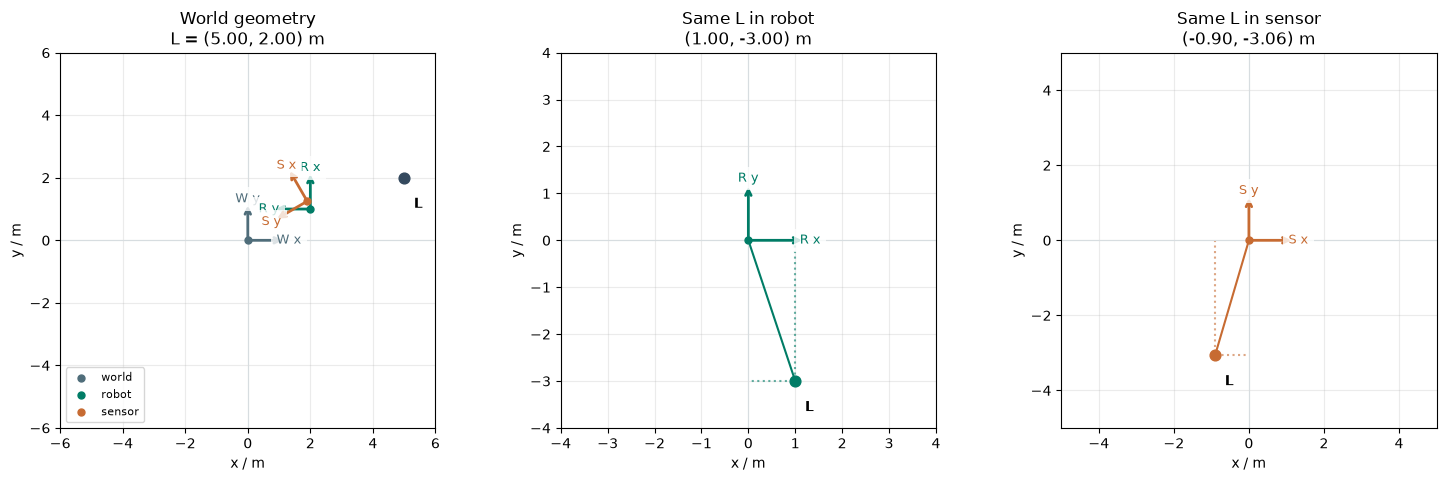

L3: world [5. 2.], robot [ 1. -3.], sensor [-0.9  -3.06] m
world_from_sensor = world_from_robot @ robot_from_sensor:
 [[-0.5   -0.866  1.9  ]
 [ 0.866 -0.5    1.25 ]
 [ 0.     0.     1.   ]]


In [10]:
# Voiceover: We learned to transform a point once. Now we join two steps by
# matching their frame names. The robot's rotation also rotates the sensor offset.
arena_landmarks = {
    "L1": np.array([-5.0, 4.0]), "L2": np.array([1.0, 4.0]),
    "L3": np.array([5.0, 2.0]), "L4": np.array([-5.0, -3.0]),
    "L5": np.array([0.0, -4.0]), "L6": np.array([5.0, -3.0]),
}

def sensor_experiment(robot_x=2.0, robot_y=1.0, heading=90.0,
                      mount_x=0.25, mount_y=0.1, mount_heading=30.0,
                      landmark_id="L3", show_wrong_order=False):
    world_from_robot = rigid_transform(robot_x, robot_y, heading)
    robot_from_sensor = rigid_transform(mount_x, mount_y, mount_heading)
    world_from_sensor = world_from_robot @ robot_from_sensor
    point_world = arena_landmarks[landmark_id]
    point_robot = transform_point(inverse_transform(world_from_robot), point_world)
    point_sensor = transform_point(inverse_transform(world_from_sensor), point_world)
    wrong = robot_from_sensor @ world_from_robot if show_wrong_order else None
    show_experiment([
        ("world", world_from_world, WORLD_COLOR),
        ("robot", world_from_robot, ROBOT_COLOR),
        ("sensor", world_from_sensor, SENSOR_COLOR),
    ], point_world, [("robot", point_robot, ROBOT_COLOR),
                     ("sensor", point_sensor, SENSOR_COLOR)], wrong_frame=wrong)
    print(f"{landmark_id}: world {point_world}, robot {point_robot}, sensor {point_sensor} m")
    print("world_from_sensor = world_from_robot @ robot_from_sensor:\n", world_from_sensor)
    sequential = transform_point(world_from_robot, transform_point(robot_from_sensor, point_sensor))
    np.testing.assert_allclose(sequential, point_world, atol=1e-12)
    if wrong is not None:
        difference = np.linalg.norm(world_from_sensor[:2, 2] - wrong[:2, 2])
        print(f"Wrong-order origin difference: {difference:.3f} m")
    return {"world_from_sensor": world_from_sensor,
            "robot": point_robot, "sensor": point_sensor}

reference = sensor_experiment()
np.testing.assert_allclose(reference["world_from_sensor"][:2, 2], [1.9, 1.25], atol=1e-12)
np.testing.assert_allclose(reference["robot"], [1, -3], atol=1e-12)
np.testing.assert_allclose(reference["sensor"],
                           [0.75 * np.sqrt(3) / 2 - 1.55,
                            -0.375 - 3.1 * np.sqrt(3) / 2], atol=1e-12)

In [11]:
# Voiceover: Start with the same mounting as the playground. Change one
# quantity at a time, then compare the two local-coordinate panels for one landmark.
sensor_lab = widgets.interactive(
    sensor_experiment,
    robot_x=slider("Robot x / m", -3, 3, 2),
    robot_y=slider("Robot y / m", -3, 3, 1),
    heading=slider("Robot yaw / deg", -180, 180, 90, step=15),
    mount_x=slider("Mount x / m", -1, 1.5, 0.25, step=0.05),
    mount_y=slider("Mount y / m", -1, 1.5, 0.1, step=0.05),
    mount_heading=slider("Mount yaw / deg", -90, 90, 30, step=15),
    landmark_id=widgets.Dropdown(options=list(arena_landmarks), value="L3",
                                  description="Landmark"),
    show_wrong_order=widgets.Checkbox(value=False, description="Show wrong order"),
)
display(sensor_lab)

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='Robot x / m', layout=Layout…

## Predict, change, explain

Use the controls above to answer these questions. Write a prediction before
changing a value, then use an axis direction or an origin in the picture to explain it.

1. In experiment 1, place the robot origin on the landmark. What are the local coordinates?
2. In experiment 2, compare $90^\circ$ and $-90^\circ$. Which coordinate changes sign?
3. In experiment 4, set both translation values to zero. What remains in the inverse?
4. In experiment 5, set robot yaw to zero and move only mount x. Which panel stays unchanged?
5. Enable the wrong-order frame. Find a configuration where the error vanishes,
   then one where it returns. Identity poses are a useful starting point.
6. Choose two landmarks. Would their physical separation change in the sensor frame?
   Verify your answer with the check below, then edit their coordinates and try again.

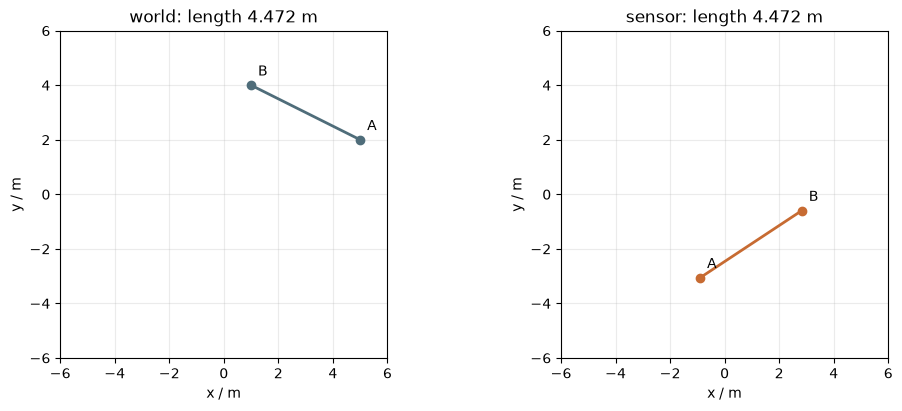

Both lengths: 4.472136 m


In [12]:
# Voiceover: A frame changes a point's coordinates, not the physical distance
# between two points. Edit these points and the pose, then compare both lengths.
point_a_world = np.array([5.0, 2.0]) # define 2 points A & B
point_b_world = np.array([1.0, 4.0])
world_from_sensor = rigid_transform(2, 1, 90) @ rigid_transform(0.25, 0.1, 30) # chain the 2 transformations
sensor_from_world = inverse_transform(world_from_sensor) # find the inverse transform so we can get sensor coordinates from world coordinates
point_a_sensor = transform_point(sensor_from_world, point_a_world) # get A & B in the sensor coordinate space
point_b_sensor = transform_point(sensor_from_world, point_b_world)
world_distance = np.linalg.norm(point_a_world - point_b_world)  # calculate the distance in both
sensor_distance = np.linalg.norm(point_a_sensor - point_b_sensor)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained") # create 2 subplots in the same row
for ax, a, b, name, color in [  # for each subplot
    (axes[0], point_a_world, point_b_world, "world", WORLD_COLOR),
    (axes[1], point_a_sensor, point_b_sensor, "sensor", SENSOR_COLOR),
]:
    ax.plot([a[0], b[0]], [a[1], b[1]], "o-", color=color, lw=2) # draw the line from A to B with o- endpoints
    ax.annotate("A", a, xytext=(5, 7), textcoords="offset points") # add text annotations
    ax.annotate("B", b, xytext=(5, 7), textcoords="offset points")
    ax.set(xlim=(-6, 6), ylim=(-6, 6), xlabel="x / m", ylabel="y / m",
           title=f"{name}: length {np.linalg.norm(a - b):.3f} m") # define limits and other settings
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)
plt.show()
plt.close(fig)
np.testing.assert_allclose(world_distance, sensor_distance, atol=1e-12)
print(f"Both lengths: {world_distance:.6f} m")

## Carry the experiment into the playground

Open the cumulative robot world using the [project guide](../../projects/robot-world/README.md).
Choose L3 and compare the table while driving and turning. World coordinates
stay fixed; robot and sensor coordinates change. The mounting is fixed at
(0.25, 0.10) meters and 30 degrees in the robot frame.

Pause and switch between the camera views. Changing the inspection camera
preserves every coordinate. The displayed axes have separate visual heights
so they remain readable; all calculations are planar.

The TypeScript transform helper uses `ml-matrix` for the same homogeneous
3 × 3 calculations explored here with NumPy. The playground keeps poses as
`{ x, y, heading }`: it builds matrices for calculation, then reads the
computed origin and orientation back into that pose representation.

We learned how to name a transformation, reverse its direction, and compose
two compatible steps. The [voiceover](../../voiceovers/002-coordinate-frames.md)
shows where each idea is implemented, in the order needed to build the feature.